First five rows of Iris dataset:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Dataset shape: (150, 4)

Dataset columns:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Dataset standardized successfully!


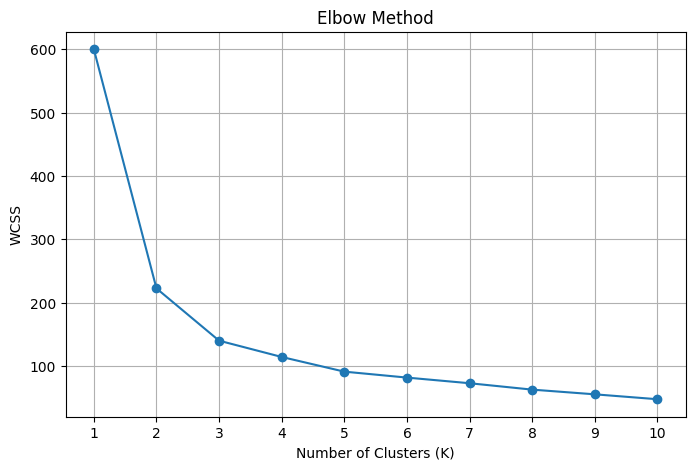


Cluster assignments:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   
5                5.4               3.9                1.7               0.4   
6                4.6               3.4                1.4               0.3   
7                5.0               3.4                1.5               0.2   
8                4.4               2.9                1.4               0.2   
9                4.9               3.1                1.5               0.1   

   Cluster  
0        1  
1        1  
2        1  
3        1  
4        1  
5        1  
6        1  
7   

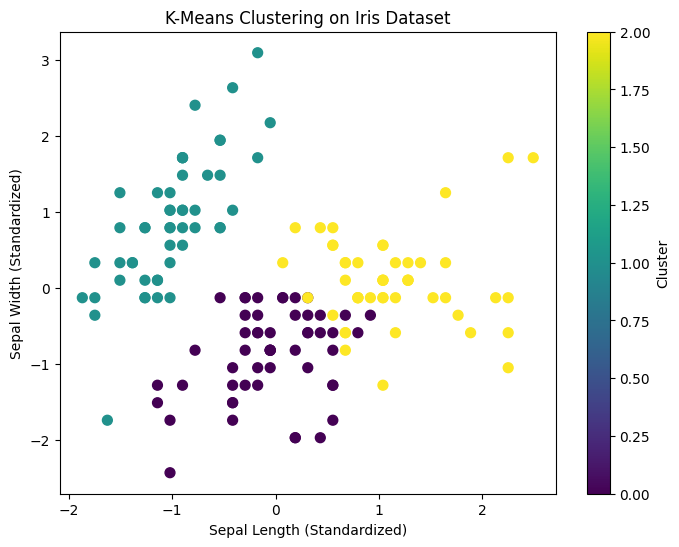


Number of flowers in each cluster:
Cluster
0    53
1    50
2    47
Name: count, dtype: int64

Comparison of Actual Species and Clusters:
Cluster          0   1   2
Actual Species            
setosa           0  50   0
versicolor      39   0  11
virginica       14   0  36

Optimal cluster count selected: 3
K-Means clustering completed successfully!


In [2]:

# ==========================================================
# EXPERIMENT NO. 4: CLUSTERING ANALYSIS USING K-MEANS
# Aim: Implement K-Means on Iris dataset and find optimal
# number of clusters using the Elbow Method.
# ==========================================================


# STEP 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Import Iris dataset
from sklearn.datasets import load_iris

# Import K-Means clustering algorithm
from sklearn.cluster import KMeans

# Import StandardScaler for feature scaling
from sklearn.preprocessing import StandardScaler


# STEP 2: Load the Iris dataset

# Load the built-in Iris dataset
iris = load_iris()

# Store feature values in X
X = iris.data

# Store actual flower names for comparison
y = iris.target

# Create a DataFrame with feature names
df = pd.DataFrame(
    X,
    columns=iris.feature_names
)

# Display first five rows
print("First five rows of Iris dataset:")
print(df.head())

# Display dataset shape
print("\nDataset shape:", df.shape)

# Display column names
print("\nDataset columns:")
print(df.columns.tolist())


# STEP 3: Standardize the dataset

# Standardization brings all features to a common scale.
# This is important because K-Means uses distance calculations.

scaler = StandardScaler()

# Fit and transform the dataset
X_scaled = scaler.fit_transform(X)

print("\nDataset standardized successfully!")


# STEP 4: Find optimal K using Elbow Method

# Store WCSS (Within Cluster Sum of Squares) values
wcss = []

# Test different cluster numbers from 1 to 10
for k in range(1, 11):

    # Create K-Means model
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    # Train the model
    kmeans.fit(X_scaled)

    # Store WCSS value
    wcss.append(kmeans.inertia_)

# Plot the Elbow graph
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    wcss,
    marker="o"
)

plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.grid(True)

plt.show()


# STEP 5: Apply K-Means with 3 clusters

# The Iris dataset has three known flower species.
# We use K=3 for this clustering experiment.

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Fit the model and predict cluster labels
clusters = kmeans.fit_predict(X_scaled)

# Add cluster labels to the DataFrame
df["Cluster"] = clusters

print("\nCluster assignments:")
print(df.head(10))


# STEP 6: Visualize the clusters

# Use the first two features for a 2D visualization.
# These are sepal length and sepal width.

plt.figure(figsize=(8, 6))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=clusters,
    cmap="viridis",
    s=50
)

plt.title("K-Means Clustering on Iris Dataset")
plt.xlabel("Sepal Length (Standardized)")
plt.ylabel("Sepal Width (Standardized)")
plt.colorbar(label="Cluster")

plt.show()


# STEP 7: Display cluster distribution

# Count the number of flowers in each cluster
print("\nNumber of flowers in each cluster:")
print(df["Cluster"].value_counts().sort_index())


# STEP 8: Compare clusters with actual species

# Add actual species names for comparison only.
df["Actual Species"] = [
    iris.target_names[i] for i in y
]

print("\nComparison of Actual Species and Clusters:")
print(
    pd.crosstab(
        df["Actual Species"],
        df["Cluster"]
    )
)


# STEP 9: Display final results

print("\nOptimal cluster count selected: 3")
print("K-Means clustering completed successfully!")


# ==========================================================
# END OF EXPERIMENT NO. 4
# ==========================================================
